# Experiment 3: Change Only the Floor with Inpainting

In Experiments 1 and 2, every method **redrew the whole image**. Even the best one (Canny + img2img) changed paintings and light, because `strength` touches every pixel.

**Idea.** Find the floor automatically, and let the model repaint **only the floor**. Everything outside this mask should stay exactly the same.

| Method | What happens |
|---|---|
| **B: Canny + img2img** (from Experiment 1) | The whole image is redrawn a little (strength 0.6) |
| **C: Canny + inpainting with a floor mask** | Only the floor is redrawn; the original pixels are put back everywhere else |

**How the mask is made.** A semantic segmentation model (SegFormer, trained on the ADE20K dataset of indoor and outdoor scenes) labels every pixel: *floor, wall, sofa, painting…* I keep only the **floor** pixels.

**Measured.** The mask lets me measure what Experiment 1 could not:
- **ΔE outside the mask**: did anything change that should not change? (lower = better)
- **ΔE inside the mask**: did the floor really change? (higher = the requested change happened)
- SSIM and edge recall **outside the mask**, and CLIP gain.

## 1. Setup

In [1]:
!pip uninstall -y torchao
!pip install -q diffusers transformers accelerate opencv-python

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


## 2. Check the GPU (must print True and Tesla T4)

In [2]:
import torch
print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))

2.11.0+cu130 True Tesla T4


## 3. Upload the same room images

In [3]:
from google.colab import files
uploaded = files.upload()
images = list(uploaded)
print(images)

Saving living-room.jpg to living-room.jpg
Saving open-plan.jpg to open-plan.jpg
Saving room.jpg to room.jpg
['living-room.jpg', 'open-plan.jpg', 'room.jpg']


## 4. Load the models (run once)
Stable Diffusion 1.5 + Canny ControlNet, the same as before. The img2img and inpainting pipelines **share** the same weights.

In [4]:
import cv2, numpy as np, pandas as pd
from PIL import Image
from diffusers import (StableDiffusionControlNetImg2ImgPipeline,
                       StableDiffusionControlNetInpaintPipeline, ControlNetModel)

dtype = torch.float16
controlnet = ControlNetModel.from_pretrained("lllyasviel/sd-controlnet-canny", torch_dtype=dtype)
pipe_i2i = StableDiffusionControlNetImg2ImgPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5",
    controlnet=controlnet, torch_dtype=dtype).to("cuda")
pipe_inp = StableDiffusionControlNetInpaintPipeline(**pipe_i2i.components)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

## 5. Find the floor with segmentation
SegFormer gives a label to every pixel. I keep the pixels labelled **floor** and grow the mask by a few pixels, so the edge between floor and wall is also repainted and no hard line stays.

preprocessor_config.json:   0%|          | 0.00/271 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/6.88k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  110MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

floor class id: 3


model.safetensors: reconstructing file:   0%|          |  0.00B /  110MB            

model.safetensors: downloading bytes:           |  0.00B            

living-room.jpg floor = 8% of the image


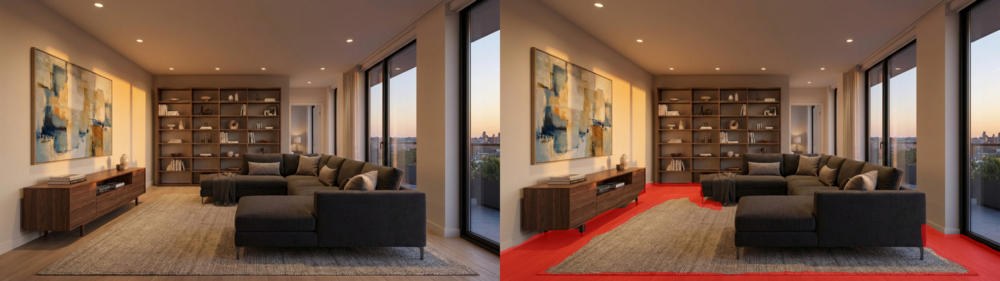

open-plan.jpg floor = 23% of the image


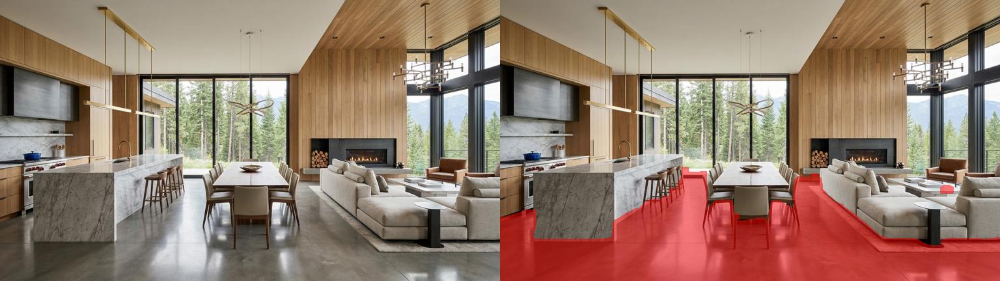

room.jpg floor = 19% of the image


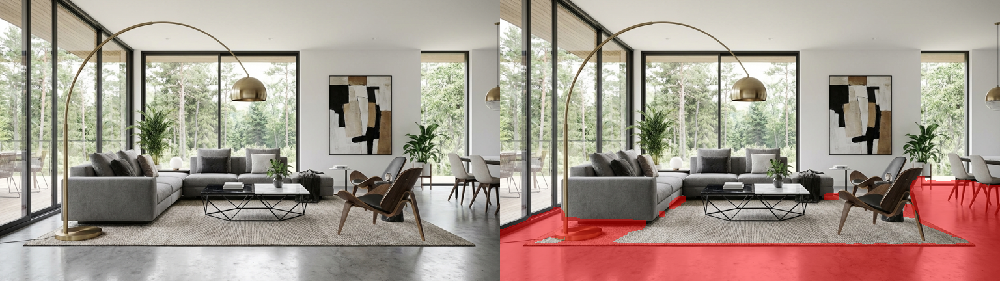

In [5]:
from transformers import SegformerImageProcessor, SegformerForSemanticSegmentation

seg_name = "nvidia/segformer-b2-finetuned-ade-512-512"
seg_proc = SegformerImageProcessor.from_pretrained(seg_name)
seg_model = SegformerForSemanticSegmentation.from_pretrained(seg_name).to("cuda").eval()
FLOOR_ID = [i for i, l in seg_model.config.id2label.items() if l.split(",")[0].strip() == "floor"][0]
print("floor class id:", FLOOR_ID)

prompt = "photorealistic interior render, light oak wooden floor, white walls, natural daylight"
negative = "blurry, distorted, low quality, deformed"
W, H = 768, 432
SEED, STEPS = 42, 25

def load_room(name):
    return Image.open(name).convert("RGB").resize((W, H))

def canny_map(room):
    e = cv2.Canny(np.array(room), 100, 200)
    return Image.fromarray(np.stack([e] * 3, axis=-1))

def floor_mask(room, grow=9):
    inputs = seg_proc(images=room, return_tensors="pt").to("cuda")
    with torch.no_grad():
        logits = seg_model(**inputs).logits
    logits = torch.nn.functional.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)
    labels = logits.argmax(1)[0].cpu().numpy()
    mask = (labels == FLOOR_ID).astype(np.uint8) * 255
    mask = cv2.dilate(mask, np.ones((grow, grow), np.uint8))
    return Image.fromarray(mask)

def overlay(room, mask):
    # show the mask in red on top of the room
    red = np.array(room).copy()
    m = np.array(mask) > 0
    red[m] = (0.5 * red[m] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    return Image.fromarray(red)

def show_row(imgs):
    row = Image.new("RGB", (W * len(imgs), H))
    for i, im in enumerate(imgs):
        row.paste(im.convert("RGB").resize((W, H)), (i * W, 0))
    display(row)
    return row

masks = {}
for name in images:
    room = load_room(name)
    masks[name] = floor_mask(room)
    print(name, f"floor = {(np.array(masks[name]) > 0).mean():.0%} of the image")
    show_row([room, overlay(room, masks[name])])   # original | floor mask in red

**Check the masks before going on.** If the floor is missed or a rug is included, the result will be wrong too. Write down what you see here.

## 6. Generate Method B and Method C
- **Method B** repeats Experiment 1 (same settings and seed, so the images should match).
- **Method C** repaints only the masked floor. After generation, the original pixels are pasted back outside the mask with a soft edge (`apply_overlay`), so the rest of the room stays exactly as it was.

Shown per room: **original | floor mask | Method B | Method C**.

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

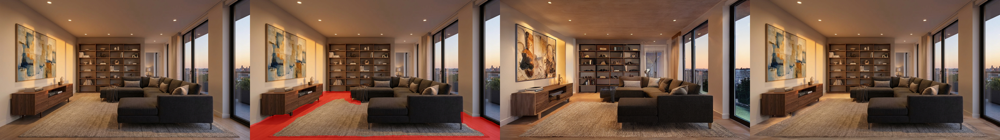

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

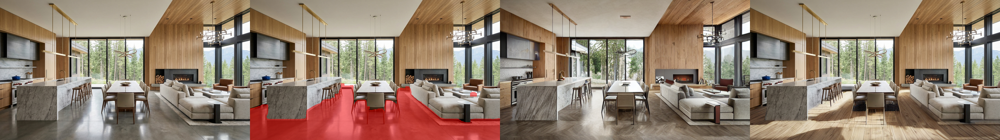

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

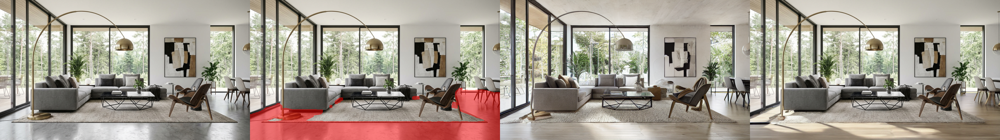

In [6]:
results = {}
for n, name in enumerate(images, start=1):
    room = load_room(name)
    edges = canny_map(room)
    mask = masks[name]

    b = pipe_i2i(prompt, negative_prompt=negative, image=room, control_image=edges,
                 strength=0.6, num_inference_steps=STEPS,
                 generator=torch.manual_seed(SEED)).images[0]

    c_raw = pipe_inp(prompt, negative_prompt=negative, image=room, mask_image=mask,
                     control_image=edges, width=W, height=H, num_inference_steps=STEPS,
                     generator=torch.manual_seed(SEED)).images[0]
    soft = pipe_inp.mask_processor.blur(mask, blur_factor=4)          # soft edge
    c = pipe_inp.image_processor.apply_overlay(soft, room, c_raw)      # original pixels outside the mask

    b.save(f"exp3_methodB_{n}.jpg", quality=90)
    c.save(f"exp3_methodC_{n}.jpg", quality=90)
    mask.save(f"exp3_mask_{n}.png")
    results[name] = (b, c)

    row = show_row([room, overlay(room, mask), b, c])
    row.save(f"exp3_comparison_{n}.jpg", quality=90)

## 7. Measure inside and outside the floor mask

In [7]:
from skimage.metrics import structural_similarity as ssim
from skimage.color import rgb2lab, deltaE_ciede2000
from transformers import CLIPModel, CLIPProcessor

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to("cuda")
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
def clip_score(img, text="a room with a light oak wooden floor"):
    inputs = clip_proc(text=[text], images=img, return_tensors="pt", padding=True).to("cuda")
    with torch.no_grad():
        out = clip(**inputs)
    return float((out.image_embeds @ out.text_embeds.T).item() * 100)

def gray(a):
    return cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)

def edge_recall_outside(orig, rend, outside):
    e_o = (cv2.Canny(orig, 100, 200) > 0) & outside
    e_r = cv2.dilate((cv2.Canny(rend, 100, 200) > 0).astype(np.uint8), np.ones((5, 5), np.uint8)) > 0
    return (e_o & e_r).sum() / max(e_o.sum(), 1)

rows = []
for n, name in enumerate(images, start=1):
    room = load_room(name); orig = np.array(room)
    inside = np.array(masks[name]) > 0
    outside = ~inside
    for method, img in zip(["B: img2img", "C: inpainting"], results[name]):
        rend = np.array(img)
        de = deltaE_ciede2000(rgb2lab(orig), rgb2lab(rend))
        ssim_map = ssim(gray(orig), gray(rend), full=True)[1]
        rows.append({"room": n, "method": method,
                     "ΔE outside ↓": de[outside].mean(),
                     "ΔE inside (floor change) ↑": de[inside].mean(),
                     "SSIM outside ↑": ssim_map[outside].mean(),
                     "Edge recall outside ↑": edge_recall_outside(orig, rend, outside),
                     "CLIP gain ↑": clip_score(img) - clip_score(room)})

df = pd.DataFrame(rows)
display(df.round(3))
summary = df.groupby("method").mean(numeric_only=True).drop(columns="room").round(3)
display(summary)

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

...

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

,room,method,ΔE outside ↓,ΔE inside (floor change) ↑,SSIM outside ↑,Edge recall outside ↑,CLIP gain ↑
0,1,B: img2img,7.830,7.386,0.638,0.922,1.128
1,1,C: inpainting,0.060,9.389,0.997,0.983,-0.189
2,2,B: img2img,9.348,9.499,0.530,0.944,3.464
3,2,C: inpainting,0.058,22.935,0.998,0.997,1.520
4,3,B: img2img,9.635,9.735,0.527,0.958,-0.046
5,3,C: inpainting,0.069,17.579,0.997,0.995,1.132


,ΔE outside ↓,ΔE inside (floor change) ↑,SSIM outside ↑,Edge recall outside ↑,CLIP gain ↑
method,,,,,
B: img2img,8.938,8.873,0.565,0.941,1.515
C: inpainting,0.062,16.634,0.997,0.992,0.821


What I saw.

- Masks: SegFormer found the floor well and left out the rugs. Thin objects that touch the floor, like chair legs and the lamp base, are partly inside the mask.
- Method B: the floor changed, but so did the paintings and the ceiling, as in Experiment 1.
- Method C: for the first time, the paintings, the light and the ceiling stayed exactly the same. The concrete floors became clearly wooden, with realistic sunlight reflections.

Result. Inpainting removed the trade-off from Experiment 1. Outside the floor, Method C changed almost nothing (mean ΔE 0.06, far below the visible limit of about 2; SSIM 0.997), while the floor itself changed about twice as much as with Method B (ΔE inside 16.6 vs 8.9).

A metric lesson. CLIP gain was lower for Method C (0.82 vs 1.52), although its floors are clearly more wooden. CLIP scores the whole image, so Method B’s wooden ceiling raised its score, and a small floor area (8% in one room) hardly moves it. CLIP is not a good metric for local edits; ΔE inside the mask measures the requested change better.

Limits. The result depends on the mask: thin objects on the floor (chair legs, the lamp base) can change because they are inside it. ΔE outside is not exactly 0 because of the soft mask edge and JPEG compression.

## 8. Download the results

In [8]:
df.to_csv("exp3_metrics.csv", index=False)
!zip -q exp3_results.zip exp3_*.jpg exp3_*.png exp3_metrics.csv
files.download("exp3_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>